## Loading of Miller ECoG data of faces/houses (+ noise)

includes some visualizations

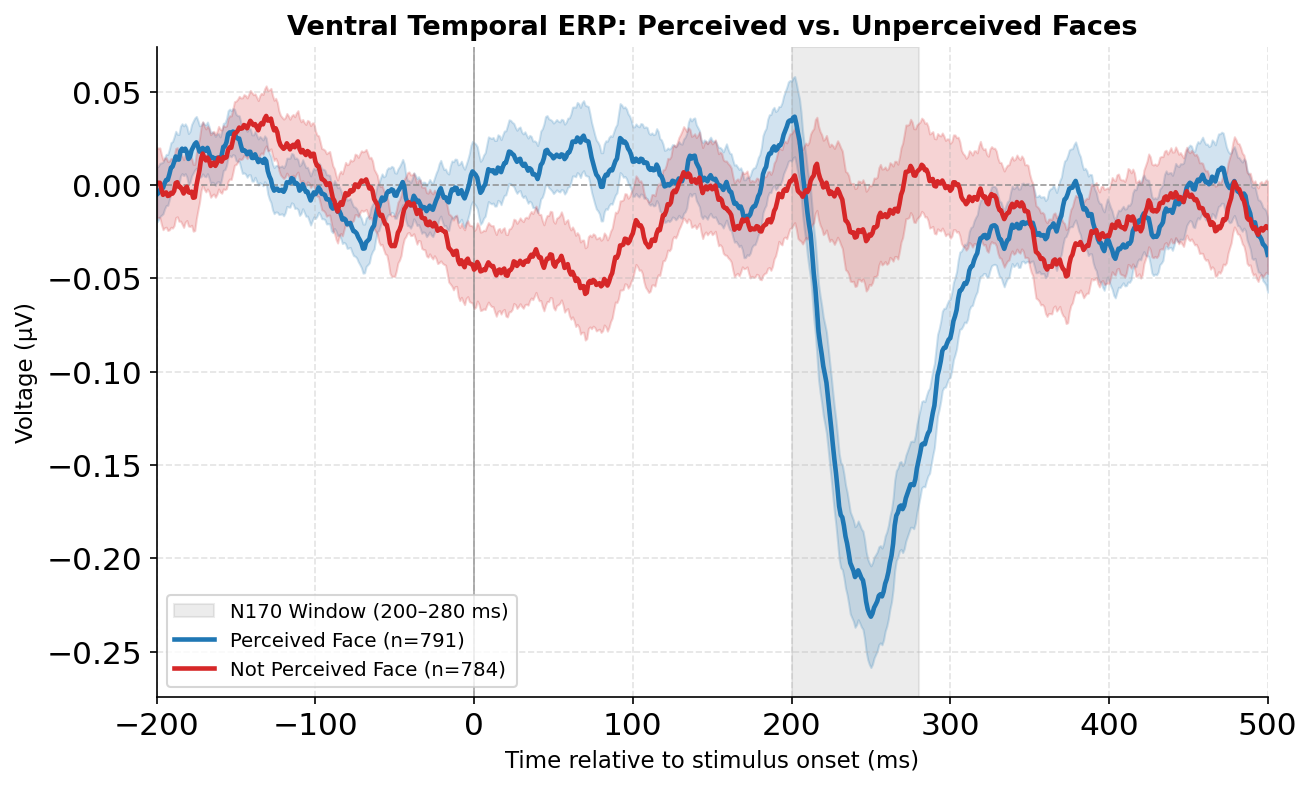

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import butter, filtfilt
from scipy.stats import sem

# =========================================================================
# Setup & Definitions
# =========================================================================
valid_sub_ids = [0, 3, 4, 5, 6]
face_channels_per_sub = {
    0: [0, 25, 30, 35, 39],
    3: [23, 24],
    4: [15],
    5: [6, 9, 15, 16, 17, 23, 24, 25, 30],
    6: [8, 9, 36, 38, 39],
}

fs = 1000
n_pre_ext, n_post_ext = 500, 1100
time_vec_ext = np.arange(-n_pre_ext, n_post_ext)

base_mask = (time_vec_ext >= -200) & (time_vec_ext < 0)
plot_mask = (time_vec_ext >= -200) & (time_vec_ext <= 500)
time_plot = time_vec_ext[plot_mask]

b_hp, a_hp = butter(4, 0.5 / (fs / 2), btype="high")

# Define condition colors
color_perceived = "#1f77b4"  # Blue
color_not_perceived = "#d62728"  # Red

records = []
trial_traces_list = []

# =========================================================================
# 1. Processing Loop & Perceptual Classification
# =========================================================================
for sub_id in valid_sub_ids:
    dat2 = alldat[sub_id][1]

    # Bad channel rejection
    V_32 = dat2["V"].astype(np.float32)
    chan_stds = np.std(V_32, axis=0)
    flat_chans = np.where(chan_stds < 1e-3)[0]
    z_stds = np.abs((chan_stds - np.mean(chan_stds)) / (np.std(chan_stds) + 1e-8))
    noisy_chans = np.where(z_stds > 3.5)[0]
    bad_chans = np.unique(np.concatenate([flat_chans, noisy_chans]))
    good_chans = np.array([c for c in range(V_32.shape[1]) if c not in bad_chans])

    # Preprocessing: CAR + High-Pass Filter
    V_car = V_32[:, good_chans] - np.mean(
        V_32[:, good_chans], axis=1, keepdims=True
    )
    V_filt = filtfilt(b_hp, a_hp, V_car, axis=0)

    mapped_face_chans = [
        np.where(good_chans == ch)[0][0]
        for ch in face_channels_per_sub[sub_id]
        if ch in good_chans
    ]

    if not mapped_face_chans:
        continue  # Skip if all face channels were flagged as bad

    t_on = np.squeeze(dat2["t_on"]).astype(int)
    stim_cat = np.squeeze(dat2["stim_cat"])
    stim_noise = np.squeeze(dat2["stim_noise"])

    # Keypress lookup optimization
    kp_raw = np.squeeze(dat2["key_press"])
    is_continuous_kp = kp_raw.ndim == 1 and len(kp_raw) > 0 and kp_raw.max() <= 1

    for i in range(len(t_on)):
        # Target face trials (stim_cat == 2) within valid boundary
        if (
            stim_cat[i] == 2
            and (t_on[i] - n_pre_ext >= 0)
            and (t_on[i] + n_post_ext <= V_filt.shape[0])
        ):
            trial_epoch = V_filt[t_on[i] - n_pre_ext : t_on[i] + n_post_ext, :]
            baseline = np.mean(trial_epoch[base_mask, :], axis=0, keepdims=True)
            trial_clean = trial_epoch - baseline

            face_trace = np.mean(trial_clean[:, mapped_face_chans], axis=1)

            # Fast direct slice check for keypress in 0-1200 ms post-onset window
            if is_continuous_kp:
                kp_in_window = np.any(kp_raw[t_on[i] : t_on[i] + 1200] > 0)
            else:
                kp_in_window = np.any(
                    (kp_raw >= t_on[i]) & (kp_raw < t_on[i] + 1200)
                )

            records.append({
                "sub_id": f"Sub_{sub_id + 1}",
                "trial_idx": i,
                "noise_level": stim_noise[i],
                "perceived": "Perceived" if kp_in_window else "Not Perceived",
            })
            trial_traces_list.append(face_trace[plot_mask])

df_perception = pd.DataFrame(records)
trial_traces_matrix = np.array(trial_traces_list)

# =========================================================================
# 2. Grand Average ERP Plot (All Subjects Pooled)
# =========================================================================
perc_mask = (df_perception["perceived"] == "Perceived").values
not_perc_mask = (df_perception["perceived"] == "Not Perceived").values

mean_perc = np.mean(trial_traces_matrix[perc_mask, :], axis=0)
sem_perc = sem(trial_traces_matrix[perc_mask, :], axis=0)

mean_not_perc = np.mean(trial_traces_matrix[not_perc_mask, :], axis=0)
sem_not_perc = sem(trial_traces_matrix[not_perc_mask, :], axis=0)

plt.figure(figsize=(9, 5.5), dpi=150)

# Shade N170 window
plt.axvspan(
    200, 280, color="gray", alpha=0.15, label="N170 Window (200–280 ms)"
)
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)
plt.axvline(0, color="gray", linestyle="-", linewidth=0.8, alpha=0.7)

# Perceived vs. Unperceived traces
plt.plot(
    time_plot,
    mean_perc,
    color=color_perceived,
    linewidth=2.2,
    label=f"Perceived Face (n={np.sum(perc_mask)})",
)
plt.fill_between(
    time_plot,
    mean_perc - sem_perc,
    mean_perc + sem_perc,
    color=color_perceived,
    alpha=0.2,
)

plt.plot(
    time_plot,
    mean_not_perc,
    color=color_not_perceived,
    linewidth=2.2,
    label=f"Not Perceived Face (n={np.sum(not_perc_mask)})",
)
plt.fill_between(
    time_plot,
    mean_not_perc - sem_not_perc,
    mean_not_perc + sem_not_perc,
    color=color_not_perceived,
    alpha=0.2,
)

plt.xlabel("Time relative to stimulus onset (ms)", fontsize=11)
plt.ylabel("Voltage (µV)", fontsize=11)
plt.title(
    "Ventral Temporal ERP: Perceived vs. Unperceived Faces",
    fontsize=13,
    fontweight="bold",
)
plt.xlim(-200, 500)
plt.grid(True, linestyle="--", alpha=0.35)

ax = plt.gca()
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.legend(loc="lower left", fontsize=9.5, frameon=True)
plt.tight_layout()
plt.show()

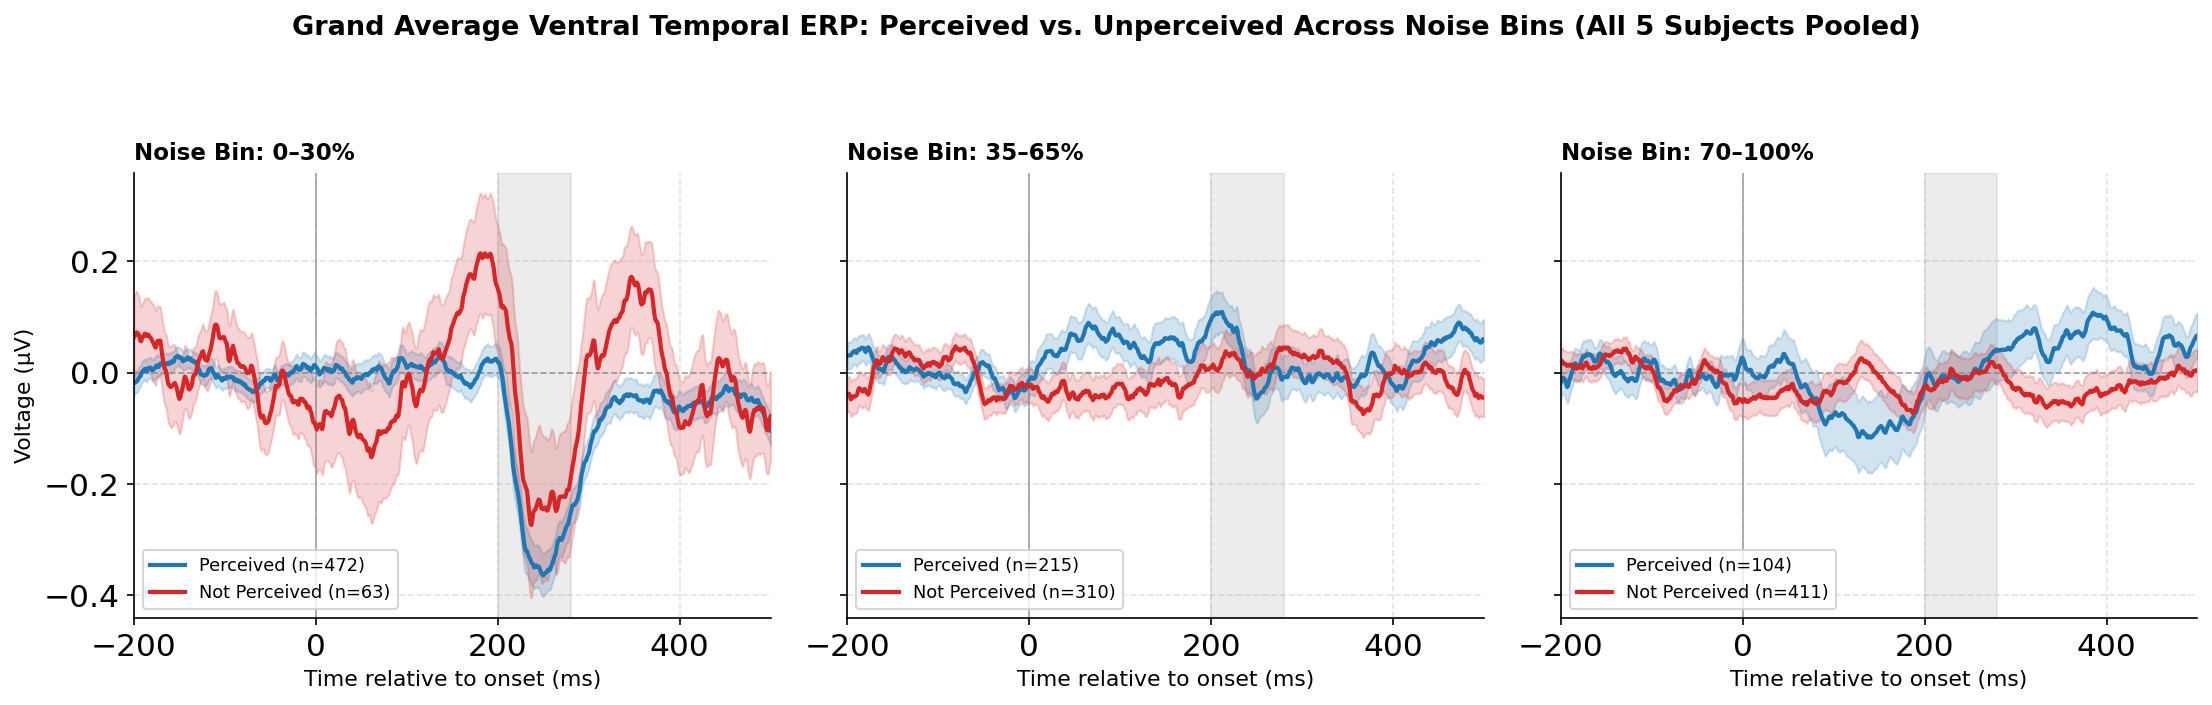

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import sem

# Define condition colors
color_perceived = "#1f77b4"      # Blue
color_not_perceived = "#d62728"  # Red

# =========================================================================
# 1. Apply 3-Bin Custom Noise Binning to df_perception
# =========================================================================
scale_factor = 100.0 if df_perception["noise_level"].max() <= 1.0 else 1.0
df_perception["noise_pct"] = df_perception["noise_level"] * scale_factor

bin_edges = [-0.1, 32.5, 67.5, 100.1]
bin_labels = ["0–30%", "35–65%", "70–100%"]
df_perception["noise_bin"] = pd.cut(
    df_perception["noise_pct"], bins=bin_edges, labels=bin_labels
)

# =========================================================================
# 2. Plot Grand-Average 1x3 Grid (All 5 Subjects Pooled)
# =========================================================================
fig, axes = plt.subplots(
    1, 3, figsize=(15, 4.5), sharex=True, sharey=True, dpi=150
)

for b_idx, label in enumerate(bin_labels):
    ax = axes[b_idx]
    bin_mask = (df_perception["noise_bin"] == label).values

    p_mask = bin_mask & (df_perception["perceived"] == "Perceived").values
    np_mask = bin_mask & (df_perception["perceived"] == "Not Perceived").values

    n_p = np.sum(p_mask)
    n_np = np.sum(np_mask)

    # Reference N170 shading (neutral gray) and zero reference axes
    ax.axvspan(200, 280, color="gray", alpha=0.15)
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)
    ax.axvline(0, color="gray", linestyle="-", linewidth=0.8, alpha=0.7)

    # Grand-average Perceived face ERP trace + SEM band (Blue)
    if n_p > 0:
        mean_p = np.mean(trial_traces_matrix[p_mask, :], axis=0)
        sem_p = sem(trial_traces_matrix[p_mask, :], axis=0)
        ax.plot(
            time_plot,
            mean_p,
            color=color_perceived,
            linewidth=2.0,
            label=f"Perceived (n={n_p})",
        )
        ax.fill_between(
            time_plot,
            mean_p - sem_p,
            mean_p + sem_p,
            color=color_perceived,
            alpha=0.2,
        )

    # Grand-average Not Perceived face ERP trace + SEM band (Red)
    if n_np > 0:
        mean_np = np.mean(trial_traces_matrix[np_mask, :], axis=0)
        sem_np = sem(trial_traces_matrix[np_mask, :], axis=0)
        ax.plot(
            time_plot,
            mean_np,
            color=color_not_perceived,
            linewidth=2.0,
            label=f"Not Perceived (n={n_np})",
        )
        ax.fill_between(
            time_plot,
            mean_np - sem_np,
            mean_np + sem_np,
            color=color_not_perceived,
            alpha=0.2,
        )

    ax.set_title(
        f"Noise Bin: {label}", fontsize=11, fontweight="bold", loc="left"
    )
    ax.set_xlim(-200, 500)
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend(loc="lower left", fontsize=8.5, frameon=True)

# Shared axis labels
for ax in axes:
    ax.set_xlabel("Time relative to onset (ms)", fontsize=10.5)
axes[0].set_ylabel("Voltage (µV)", fontsize=10.5)

plt.suptitle(
    "Grand Average Ventral Temporal ERP: Perceived vs. Unperceived Across Noise Bins (All 5 Subjects Pooled)",
    y=1.05,
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.show()

In [7]:
import pandas as pd

# =========================================================================
# 1. Ensure 3-Bin Custom Noise Binning is Applied to df_perception
# =========================================================================
scale_factor = 100.0 if df_perception["noise_level"].max() <= 1.0 else 1.0
df_perception["noise_pct"] = df_perception["noise_level"] * scale_factor

bin_edges = [-0.1, 32.5, 67.5, 100.1]
bin_labels = ["0–30%", "35–65%", "70–100%"]
df_perception["noise_bin"] = pd.cut(
    df_perception["noise_pct"], bins=bin_edges, labels=bin_labels
)

# =========================================================================
# 2. Cross-tabulate trial counts per subject, noise bin, and perception status
# =========================================================================
imbalance_table = pd.crosstab(
    [df_perception["sub_id"], df_perception["noise_bin"]],
    df_perception["perceived"],
    margins=True,
)

print("--- Trial Counts per Subject and 3 Noise Bins ---")
print(imbalance_table)

--- Trial Counts per Subject and 3 Noise Bins ---
perceived         Not Perceived  Perceived   All
sub_id noise_bin                                
Sub_1  0–30%                 11         96   107
       35–65%                72         33   105
       70–100%              100          3   103
Sub_4  0–30%                  4        103   107
       35–65%                75         30   105
       70–100%              100          3   103
Sub_5  0–30%                 38         69   107
       35–65%                83         22   105
       70–100%              100          3   103
Sub_6  0–30%                  3        104   107
       35–65%                36         69   105
       70–100%               49         54   103
Sub_7  0–30%                  7        100   107
       35–65%                44         61   105
       70–100%               62         41   103
All                         784        791  1575


In [8]:
import numpy as np
import pandas as pd

# =========================================================================
# 1. Ensure 3-Bin Custom Noise Binning is Applied to df_perception
# =========================================================================
scale_factor = 100.0 if df_perception["noise_level"].max() <= 1.0 else 1.0
df_perception["noise_pct"] = df_perception["noise_level"] * scale_factor

bin_edges = [-0.1, 32.5, 67.5, 100.1]
bin_labels = ["0–30%", "35–65%", "70–100%"]
df_perception["noise_bin"] = pd.cut(
    df_perception["noise_pct"], bins=bin_edges, labels=bin_labels
)

# =========================================================================
# 2. Within-Subject & Within-Bin Random Subsampling (Class Balancing)
# =========================================================================
np.random.seed(42)  # Set seed for reproducible random subsampling

balanced_indices = []

# Group by subject and noise bin to balance within-subject conditions
for (sub_id, bin_label), group in df_perception.groupby(
    ["sub_id", "noise_bin"], observed=False
):
    perc_idx = group[group["perceived"] == "Perceived"].index
    not_perc_idx = group[group["perceived"] == "Not Perceived"].index

    # Find minority class count
    n_min = min(len(perc_idx), len(not_perc_idx))

    # Sample n_min trials from both conditions without replacement
    if n_min > 0:
        sampled_perc = np.random.choice(perc_idx, size=n_min, replace=False)
        sampled_not_perc = np.random.choice(
            not_perc_idx, size=n_min, replace=False
        )
        balanced_indices.extend(sampled_perc)
        balanced_indices.extend(sampled_not_perc)

# Extract balanced DataFrame and matrix subset
df_balanced = df_perception.loc[balanced_indices].copy()
balanced_traces_matrix = trial_traces_matrix[balanced_indices, :]

print(f"Original total trials: {len(df_perception)}")
print(f"Balanced total trials: {len(df_balanced)}")

# Verify balanced counts
print("\n--- Balanced Trial Counts across 3 Noise Bins ---")
print(
    pd.crosstab(
        [df_balanced["sub_id"], df_balanced["noise_bin"]],
        df_balanced["perceived"],
    )
)

Original total trials: 1575
Balanced total trials: 654

--- Balanced Trial Counts across 3 Noise Bins ---
perceived         Not Perceived  Perceived
sub_id noise_bin                          
Sub_1  0–30%                 11         11
       35–65%                33         33
       70–100%                3          3
Sub_4  0–30%                  4          4
       35–65%                30         30
       70–100%                3          3
Sub_5  0–30%                 38         38
       35–65%                22         22
       70–100%                3          3
Sub_6  0–30%                  3          3
       35–65%                36         36
       70–100%               49         49
Sub_7  0–30%                  7          7
       35–65%                44         44
       70–100%               41         41


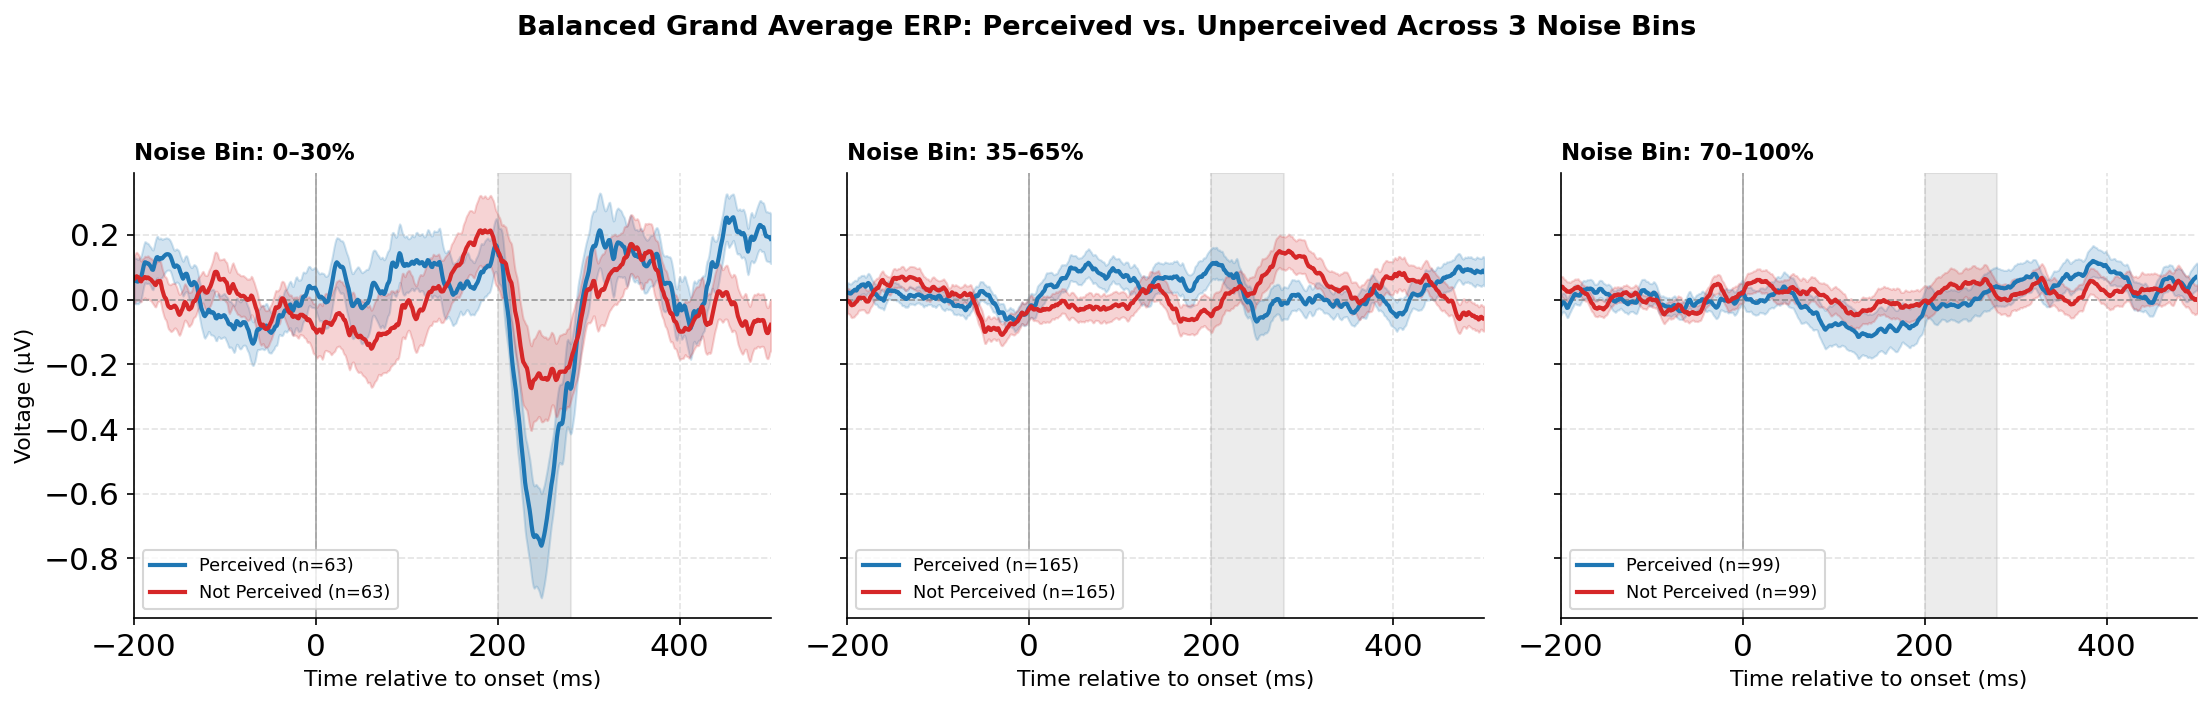

In [9]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import sem

# Define condition colors
color_perceived = "#1f77b4"      # Blue
color_not_perceived = "#d62728"  # Red

# =========================================================================
# 1. Ensure 3-Bin Custom Noise Binning
# =========================================================================
bin_labels = ["0–30%", "35–65%", "70–100%"]

# =========================================================================
# 2. Plot Balanced Grand-Average 1x3 Grid
# =========================================================================
fig, axes = plt.subplots(
    1, 3, figsize=(15, 4.5), sharex=True, sharey=True, dpi=150
)

for b_idx, label in enumerate(bin_labels):
    ax = axes[b_idx]
    bin_mask = (df_balanced["noise_bin"] == label).values

    p_mask = bin_mask & (df_balanced["perceived"] == "Perceived").values
    np_mask = bin_mask & (df_balanced["perceived"] == "Not Perceived").values

    n_p = np.sum(p_mask)
    n_np = np.sum(np_mask)

    # Neutral N170 shading and zero reference axes
    ax.axvspan(200, 280, color="gray", alpha=0.15)
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)
    ax.axvline(0, color="gray", linestyle="-", linewidth=0.8, alpha=0.7)

    # Plot balanced Perceived traces (Blue)
    if n_p > 0:
        mean_p = np.mean(balanced_traces_matrix[p_mask, :], axis=0)
        sem_p = sem(balanced_traces_matrix[p_mask, :], axis=0)
        ax.plot(
            time_plot,
            mean_p,
            color=color_perceived,
            linewidth=2.0,
            label=f"Perceived (n={n_p})",
        )
        ax.fill_between(
            time_plot,
            mean_p - sem_p,
            mean_p + sem_p,
            color=color_perceived,
            alpha=0.2,
        )

    # Plot balanced Not Perceived traces (Red)
    if n_np > 0:
        mean_np = np.mean(balanced_traces_matrix[np_mask, :], axis=0)
        sem_np = sem(balanced_traces_matrix[np_mask, :], axis=0)
        ax.plot(
            time_plot,
            mean_np,
            color=color_not_perceived,
            linewidth=2.0,
            label=f"Not Perceived (n={n_np})",
        )
        ax.fill_between(
            time_plot,
            mean_np - sem_np,
            mean_np + sem_np,
            color=color_not_perceived,
            alpha=0.2,
        )

    ax.set_title(
        f"Noise Bin: {label}", fontsize=11, fontweight="bold", loc="left"
    )
    ax.set_xlim(-200, 500)
    ax.grid(True, linestyle="--", alpha=0.35)
    ax.legend(loc="lower left", fontsize=8.5, frameon=True)

# Shared axis labels
for ax in axes:
    ax.set_xlabel("Time relative to onset (ms)", fontsize=10.5)
axes[0].set_ylabel("Voltage (µV)", fontsize=10.5)

plt.suptitle(
    "Balanced Grand Average ERP: Perceived vs. Unperceived Across 3 Noise Bins",
    y=1.05,
    fontsize=13,
    fontweight="bold",
)
plt.tight_layout()
plt.show()